In [1]:
!pip install pandas numpy scikit-learn seaborn matplotlib openpyxl

<Axes: >

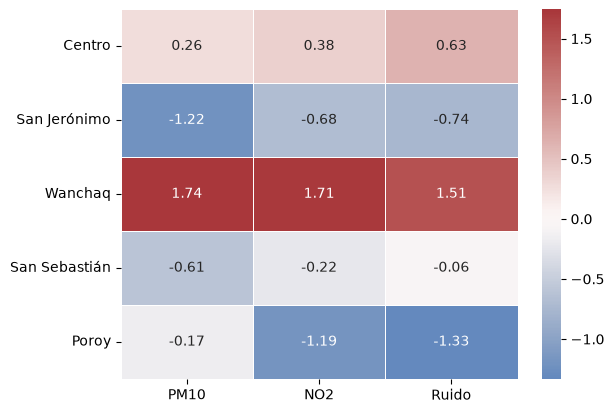

In [7]:
import seaborn as sns
sns.heatmap(df_z, cmap='vlag', center=0, annot=True, fmt='.2f', linewidths=0.5)


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame({
    'PM10': [45.0, 28.0, 62.0, 35.0, np.nan],
    'NO2':  [18.2, 12.5, 25.4, 15.0, 9.8],
    'Ruido':[72, 58, 81, 65, 52]
}, index=['Centro', 'San Jerónimo', 'Wanchaq', 'San Sebastián', 'Poroy'])

df_clean = df.fillna(df.median())
print(df_clean)   # PM10 de Poroy = 40.0

               PM10   NO2  Ruido
Centro         45.0  18.2     72
San Jerónimo   28.0  12.5     58
Wanchaq        62.0  25.4     81
San Sebastián  35.0  15.0     65
Poroy          40.0   9.8     52


In [3]:
scaler = StandardScaler()
df_z = pd.DataFrame(scaler.fit_transform(df_clean),
                    index=df_clean.index, columns=df_clean.columns)
print(df_z.round(2))

               PM10   NO2  Ruido
Centro         0.26  0.38   0.63
San Jerónimo  -1.22 -0.68  -0.74
Wanchaq        1.74  1.71   1.51
San Sebastián -0.61 -0.22  -0.06
Poroy         -0.17 -1.19  -1.33


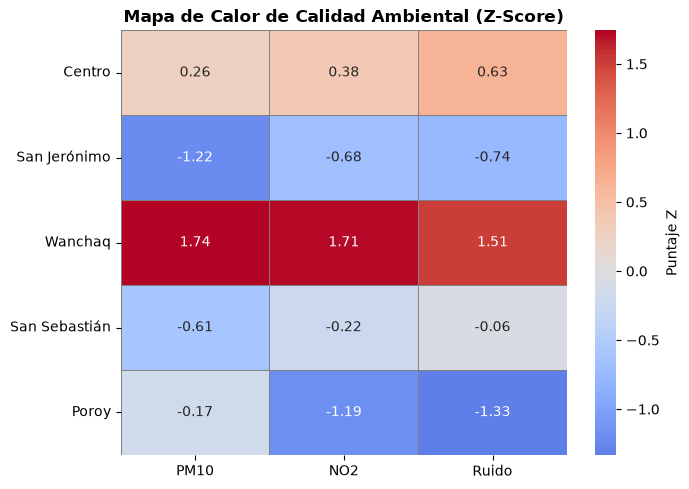

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_z, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            linewidths=0.5, linecolor='gray', cbar_kws={'label': 'Puntaje Z'})
plt.title('Mapa de Calor de Calidad Ambiental (Z-Score)', fontweight='bold')
plt.tight_layout()
plt.show()

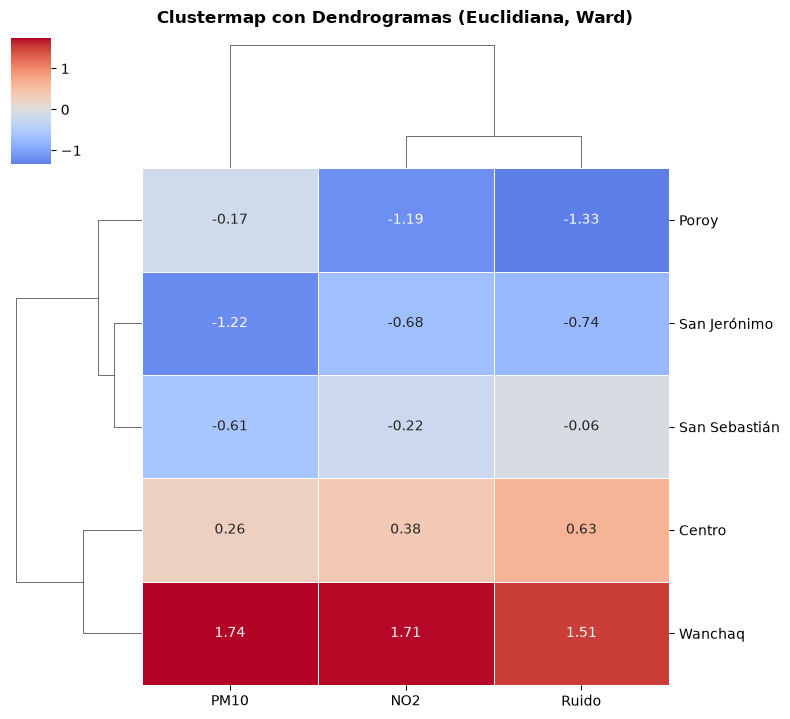

In [5]:
g = sns.clustermap(df_z, metric='euclidean', method='ward',
                   cmap='coolwarm', center=0, annot=True, fmt='.2f',
                   linewidths=0.5, figsize=(8, 7))
g.fig.suptitle('Clustermap con Dendrogramas (Euclidiana, Ward)',
               fontweight='bold', y=1.02)
g.savefig('clustermap_python_300dpi.png', dpi=300, bbox_inches='tight')
plt.show()